In [14]:
# Setup: imports, file paths, memmap helpers
import numpy as np
import matplotlib.pyplot as plt
import os
from numpy.fft import fft, fftshift, fftfreq

# Notebook plotting defaults
%matplotlib inline
plt.rcParams.update({
    'figure.figsize': (12, 4),
    'axes.grid': True
})

# Data config (adjust path if needed)
filename = '../ds2.bin'  # path relative to this notebook
fs = 25_000_000          # sample rate (Hz)
bytes_per_sample = 4     # 2 bytes I + 2 bytes Q (int16)

# Analysis window in seconds
t_start = 60.0
t_end   = 300.0
assert t_end > t_start, 't_end must be > t_start'

# File checks
if not os.path.exists(filename):
    raise FileNotFoundError(f'Arquivo não encontrado: {filename}')

total_bytes = os.path.getsize(filename)
N_int16 = total_bytes // 2
N_samples = total_bytes // bytes_per_sample  # complex samples (I,Q)
print(f'Arquivo: {filename}\n- Tamanho: {total_bytes:,} bytes\n- Amostras complexas: {N_samples:,}\n- Duração aprox: {N_samples/fs:.2f} s')

# Open memmap once (read-only)
mm = np.memmap(filename, dtype=np.int16, mode='r', shape=(N_int16,))

# Helper: read a short complex window centered at time t (seconds)
# Returns complex64 array of length win_N
# Guard-rails: clamps to file bounds

def read_window_at_time(t_sec: float, win_N: int) -> np.ndarray:
    ctr = int(t_sec * fs)
    half = win_N // 2
    start = max(0, ctr - half)
    end = min(N_samples, start + win_N)
    # ensure exact length when near boundaries
    start = max(0, end - win_N)
    i0 = 2 * start
    i1 = 2 * end
    seg = mm[i0:i1]
    I = seg[0::2].astype(np.float32)
    Q = seg[1::2].astype(np.float32)
    return I + 1j * Q

# Helper: integrate power in a 2 MHz band around DC via FFT
# Returns linear power and power in dB

def inband_power_2mhz(x: np.ndarray) -> tuple[float, float]:
    N = len(x)
    # Hann window to reduce spectral leakage
    w = np.hanning(N).astype(np.float32)
    X = fftshift(fft(x * w))
    freqs = fftshift(fftfreq(N, d=1/fs))
    mask = np.abs(freqs) <= 1_000_000.0  # ±1 MHz band
    # Power spectral density ~ |X|^2, integrate over selected bins
    p_lin = float(np.sum(np.abs(X[mask])**2) / np.sum(w**2))
    p_db = 10.0 * np.log10(p_lin + 1e-20)
    return p_lin, p_db

# Helper: spectral centroid within ±1 MHz as Doppler proxy (Hz)

def doppler_proxy_centroid(x: np.ndarray) -> float:
    N = len(x)
    w = np.hanning(N).astype(np.float32)
    X = fftshift(fft(x * w))
    freqs = fftshift(fftfreq(N, d=1/fs))
    mask = np.abs(freqs) <= 1_000_000.0
    P = (np.abs(X)**2)[mask]
    F = freqs[mask]
    denom = float(np.sum(P)) + 1e-30
    return float(np.sum(F * P) / denom)

# Helper: lag-1 normalized autocorr phase (phase-perturbation proxy)

def lag1_autocorr_phase(x: np.ndarray) -> float:
    # Normalize to unit power to make measure scale-invariant
    if len(x) < 2:
        return 0.0
    xn = x / (np.sqrt(np.mean(np.abs(x)**2)) + 1e-20)
    r1 = np.vdot(xn[:-1], xn[1:]) / (len(xn) - 1)
    return float(np.angle(r1))


Arquivo: ../ds2.bin
- Tamanho: 45,717,913,600 bytes
- Amostras complexas: 11,429,478,400
- Duração aprox: 457.18 s


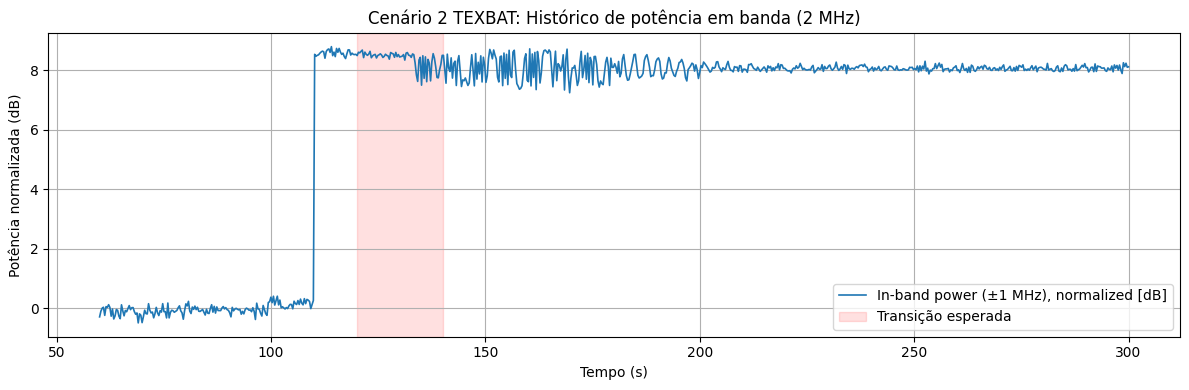

Delta dB (pós - pré): 8.053428056456474 dB


In [15]:
# 1) Time history of normalized in-band (±1 MHz) power, 60–160 s
# Strategy: sample ~800 time points; each point reads a short window (32768 samples ≈ 1.31 ms)
# and integrates PSD within ±1 MHz. Normalize to pre-attack median (t < 120 s) and plot in dB.

np.random.seed(0)

n_points = 800
win_N = 32768  # keep power-of-two FFT, ~1.31 ms at 25 Msps

# time grid (inclusive of endpoints)
T = np.linspace(t_start, t_end, n_points)

power_lin = np.empty(n_points, dtype=np.float64)
power_db = np.empty(n_points, dtype=np.float64)
centroid_hz = np.empty(n_points, dtype=np.float64)
phi_lag1 = np.empty(n_points, dtype=np.float64)

for i, t in enumerate(T):
    x = read_window_at_time(float(t), win_N)
    p_lin, p_db = inband_power_2mhz(x)
    power_lin[i] = p_lin
    power_db[i] = p_db
    centroid_hz[i] = doppler_proxy_centroid(x)
    phi_lag1[i] = lag1_autocorr_phase(x)

# Normalize power to pre-attack baseline
pre_mask = T < 120.0
baseline = np.median(power_lin[pre_mask]) if np.any(pre_mask) else np.median(power_lin)
power_norm_db = 10.0 * np.log10((power_lin / (baseline + 1e-30)) + 1e-30)

fig, ax = plt.subplots(1, 1, figsize=(12, 4))
ax.plot(T, power_norm_db, '-', lw=1.2, label='In-band power (±1 MHz), normalized [dB]')
ax.axvspan(120, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('Potência normalizada (dB)')
ax.set_title('Cenário 2 TEXBAT: Histórico de potência em banda (2 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

# Quick stats around transition
print('Delta dB (pós - pré):', float(np.median(power_norm_db[T>140]) - np.median(power_norm_db[T<120])), 'dB')

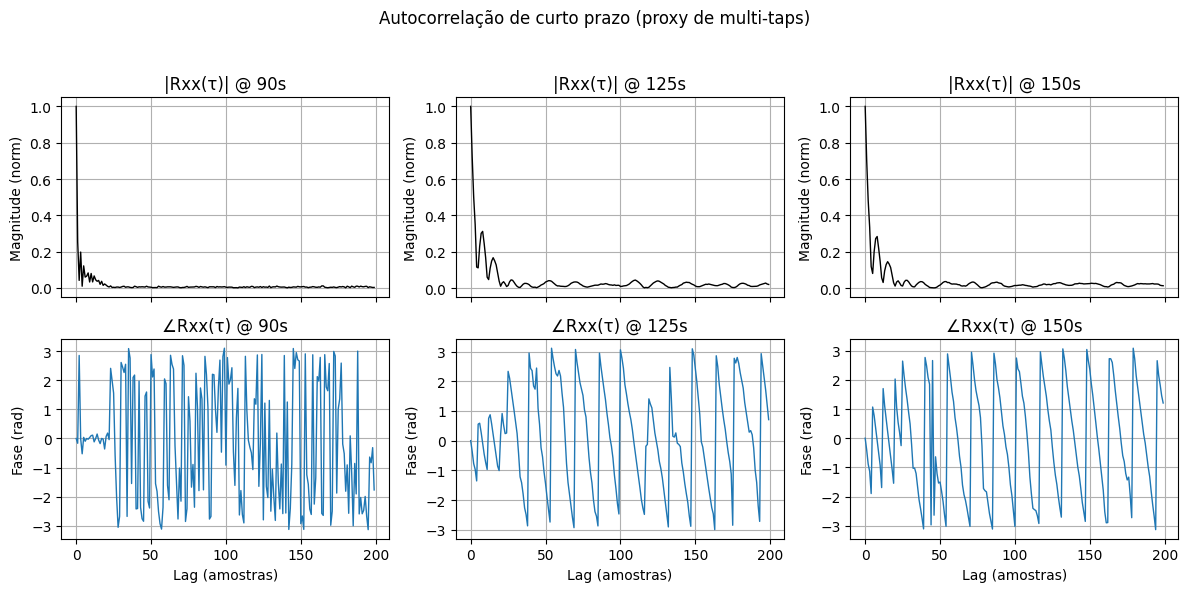

In [16]:
# 4) Correlation proxy (multi-tap) via short-time autocorrelation
# We examine autocorrelation over small lags for three times: pre, during, post
select_times = [90.0, 125.0, 150.0]  # s (adjust if needed)
win_N_corr = 65536  # ~2.62 ms window for better lag resolution
max_lag = 200  # complex lags to show (samples)

fig, axes = plt.subplots(2, len(select_times), figsize=(4*len(select_times), 6), sharex='col')
for k, t0 in enumerate(select_times):
    x = read_window_at_time(t0, win_N_corr)
    # band-limit implicitly via Hann before autocorr
    xw = x * np.hanning(len(x))
    # Biased autocorrelation via FFT (fast)
    X = np.fft.fft(xw, n=2*len(xw))
    r_full = np.fft.ifft(np.abs(X)**2)
    r = r_full[:max_lag]

    lags = np.arange(len(r))
    axes[0, k].plot(lags, np.abs(r) / (np.abs(r[0]) + 1e-20), '-k', lw=1.0)
    axes[0, k].set_title(f'|Rxx(τ)| @ {t0:.0f}s')
    axes[0, k].set_ylabel('Magnitude (norm)')
    axes[0, k].grid(True)

    axes[1, k].plot(lags, np.angle(r), '-', lw=1.0)
    axes[1, k].set_title(f'∠Rxx(τ) @ {t0:.0f}s')
    axes[1, k].set_xlabel('Lag (amostras)')
    axes[1, k].set_ylabel('Fase (rad)')
    axes[1, k].grid(True)

plt.suptitle('Autocorrelação de curto prazo (proxy de multi-taps)')
plt.tight_layout(rect=(0,0,1,0.95))
plt.show()

## Interpretação esperada (Cenário 2 TEXBAT)

- Potência em banda (±1 MHz):
  - Antes do ataque (~60–120 s), a curva normalizada deveria oscilar em torno de 0 dB.
  - Durante a transição (~120–140 s), espera-se um aumento abrupto/gradual positivo (overpower).
  - Após (~>140 s), um novo patamar (acima de 0 dB) pode se manter se o spoofer dominar.

- Proxy de Doppler (centro espectral):
  - Pré-ataque: variações pequenas em torno de 0 Hz (baseband), sem tendência comum pronunciada.
  - Transição: desvio sistemático (rampa/curva) sugerindo manobra do spoofer; valores se deslocam e depois estabilizam.
  - Pós-ataque: novo centro médio, estável.

- Proxy de perturbação de fase (lag-1 autocorr phase, z-score):
  - Pré: z-scores próximos de 0 (ruído normal do canal).
  - Transição: picos acima de 5σ indicam "phase trauma" (mudança rápida de dinâmica de fase).
  - Pós: retorno a níveis moderados, mas possivelmente com offset.

- Autocorrelação (proxy de multi-taps):
  - Pré: |Rxx(τ)| decai suave, fase sem oscilações regulares.
  - Durante: surgem ondulações/oscilações (batimentos) em |Rxx(τ)| e variações sistemáticas em ∠Rxx(τ), indicando interação entre componentes (autêntico + falso).
  - Pós: padrão diferente do pré (domínio do falso), com assinatura mais estável.

Observações e limitações:
- Estes são proxies de baixo custo computacional sobre o sinal IF/baseband. Métricas clássicas como C/N0 por canal e correlação complexa em múltiplos taps (early/prompt/late por PRN) requerem uma etapa de despreading (gerar C/A code, wipeoff de portadora, busca de Doppler) e seriam mais diagnósticas; posso adicionar uma célula de aquisição simplificada para um PRN específico se quiser.
- Assumo sinal centrado em DC; se o IF não for zero-IF, podemos recentrar (mixar) ou ajustar a máscara de frequências na integração (mudar a banda ao redor do IF conhecido).


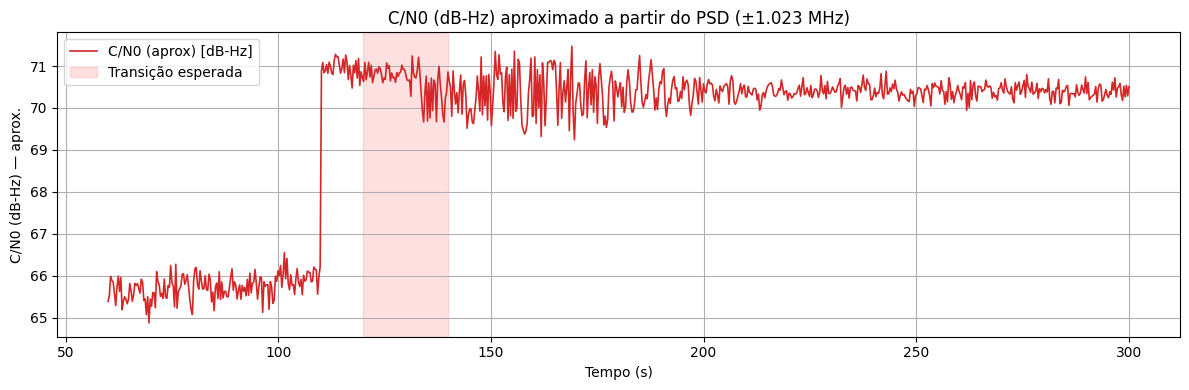

C/N0 pré (mediana, t<120s):  65.820763676967 dB-Hz
C/N0 pós (mediana, t>140s):  70.40503089184737 dB-Hz
Δ (pós - pré):  4.58426721488037 dB-Hz


In [17]:
# 5) C/N0 (dB-Hz) — estimativa por PSD (sem despreading)
# Atenção: é uma aproximação de tendência (não absoluta), baseada em:
# - Centro espectral (fc) por centróide em ±2 MHz
# - Banda do sinal: ±1.023 MHz
# - N0 estimado nas bandas de ruído: 1.5–3.5 MHz (ambos os lados)
# Fórmula: C/N0 ≈ (P_band - N0 * B_sig) / N0  [Hz]  → 10*log10(·) em dB-Hz

win_N_cn0 = 32768  # mesmo tamanho de janela
B_sig = 2 * 1.023e6

def estimate_cn0_dbhz(x: np.ndarray) -> float:
    N = len(x)
    w = np.hanning(N).astype(np.float32)
    X = fftshift(fft(x * w))
    f = fftshift(fftfreq(N, d=1/fs))
    # Periodograma (dois lados) por Hz
    S = (np.abs(X)**2) / (fs * np.sum(w**2))
    df = f[1] - f[0]

    # Estimar fc pelo centróide em ±2 MHz
    band2 = np.abs(f) <= 2.0e6
    S2 = S[band2]
    f2 = f[band2]
    denom = np.sum(S2) + 1e-30
    fc = float(np.sum(f2 * S2) / denom)

    # Máscaras de banda do sinal e bandas de ruído
    sig_mask = np.abs(f - fc) <= 1.023e6
    noise_mask = (np.abs(f - fc) >= 1.5e6) & (np.abs(f - fc) <= 3.5e6)

    # N0 por mediana (robusto)
    if not np.any(noise_mask):
        return np.nan
    N0 = float(np.median(S[noise_mask]))

    # Potência integrada na banda do sinal
    P_band = float(np.sum(S[sig_mask]) * df)

    # C estimado e C/N0
    C_est = max(P_band - N0 * B_sig, 1e-30)
    CNo = C_est / (N0 + 1e-30)  # Hz
    return 10.0 * np.log10(CNo)

CNo_dbHz = np.empty_like(T)
for i, t in enumerate(T):
    x = read_window_at_time(float(t), win_N_cn0)
    CNo_dbHz[i] = estimate_cn0_dbhz(x)

fig, ax = plt.subplots(1,1, figsize=(12,4))
ax.plot(T, CNo_dbHz, '-', lw=1.2, color='C3', label='C/N0 (aprox) [dB-Hz]')
ax.axvspan(120, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('C/N0 (dB-Hz) — aprox.')
ax.set_title('C/N0 (dB-Hz) aproximado a partir do PSD (±1.023 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

print('C/N0 pré (mediana, t<120s): ', float(np.nanmedian(CNo_dbHz[T<120])), 'dB-Hz')
print('C/N0 pós (mediana, t>140s): ', float(np.nanmedian(CNo_dbHz[T>140])), 'dB-Hz')
print('Δ (pós - pré): ', float(np.nanmedian(CNo_dbHz[T>140]) - np.nanmedian(CNo_dbHz[T<120])), 'dB-Hz')

## Notas sobre a estimativa de C/N0

- Esta métrica é aproximada porque não fazemos despreading por PRN (onde C é realmente a potência pós-correlação). Mesmo assim, ela é útil para ver tendências: durante o overpower do spoofer, o valor estimado de C/N0 sobe.
- Se o IF não for zero-IF, a detecção de fc por centróide compensa descentragens moderadas. Se houver interferência narrowband, troque a mediana por média truncada nas bandas de ruído.
- Para C/N0 absoluto por satélite, o caminho correto é: gerar C/A code de um PRN, wipeoff de portadora com um Doppler, correlacionar (early/prompt/late) e aplicar estimadores clássicos (por exemplo, relação entre sinal e ruído nos correlators). Posso adicionar essa etapa para um PRN de interesse.


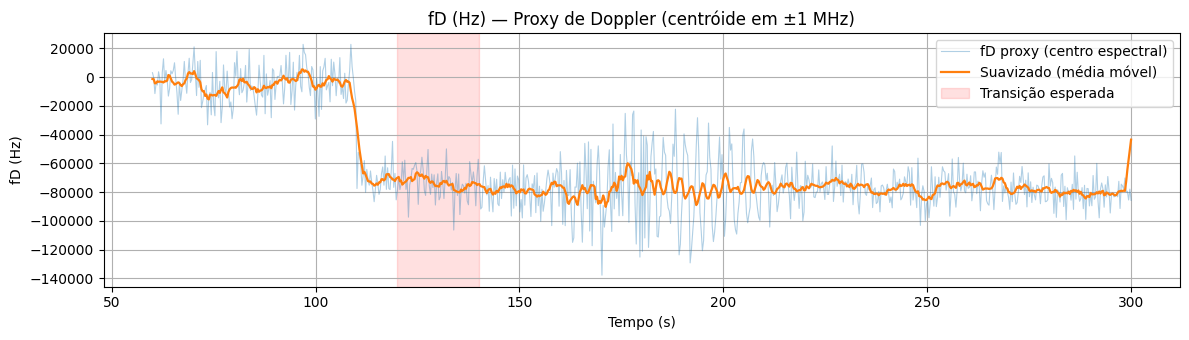

fD pré (mediana, t<120s):  -7433.655268793633 Hz
fD pós (mediana, t>140s):  -77372.6718009271 Hz
Δ fD (pós - pré):  -69939.01653213346 Hz


In [18]:
# fD (Hz) — Proxy de Doppler via centróide espectral (±1 MHz)
# Reusa centroid_hz e T; se não existirem, calcula rapidamente.
try:
    _ = centroid_hz
    _ = T
    _ = win_N
except NameError:
    n_points = 800
    win_N = 32768
    T = np.linspace(t_start, t_end, n_points)
    centroid_hz = np.empty(n_points, dtype=np.float64)
    for i, t in enumerate(T):
        x = read_window_at_time(float(t), win_N)
        centroid_hz[i] = doppler_proxy_centroid(x)

# Suavização leve para visualização
w = 11 if len(centroid_hz) >= 11 else (len(centroid_hz) // 5 * 2 + 1)
if w and w >= 3 and w % 2 == 1:
    k = np.ones(w) / w
    centroid_smooth = np.convolve(centroid_hz, k, mode='same')
else:
    centroid_smooth = centroid_hz.copy()

fig, ax = plt.subplots(1,1, figsize=(12,3.5))
ax.plot(T, centroid_hz, color='C0', alpha=0.35, lw=0.8, label='fD proxy (centro espectral)')
ax.plot(T, centroid_smooth, color='C1', lw=1.6, label='Suavizado (média móvel)')
ax.axvspan(120, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('fD (Hz)')
ax.set_title('fD (Hz) — Proxy de Doppler (centróide em ±1 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

print('fD pré (mediana, t<120s): ', float(np.median(centroid_hz[T<120])), 'Hz')
print('fD pós (mediana, t>140s): ', float(np.median(centroid_hz[T>140])), 'Hz')
print('Δ fD (pós - pré): ', float(np.median(centroid_hz[T>140]) - np.median(centroid_hz[T<120])), 'Hz')

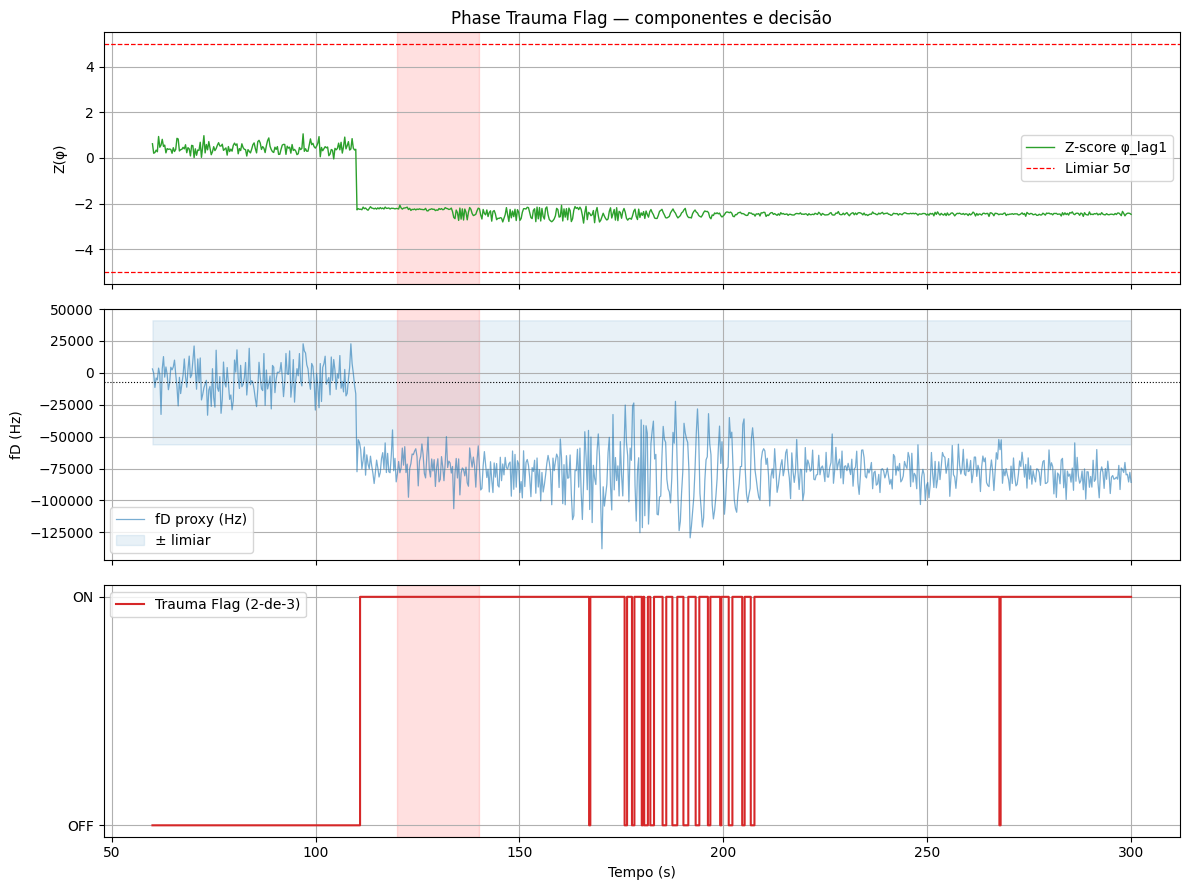

Flag ON (total): 74.0% | pré: 15.0% | transição: 100.0% | pós: 92.9%


In [19]:
# Phase Trauma Flag — combinação de fase (z-score) e desvio de Doppler
# Reusa z_phi e centroid_hz se existirem; caso contrário, recalcula rapidamente.
try:
    _ = z_phi
    _ = centroid_hz
    _ = T
    _ = win_N
except NameError:
    n_points = 800
    win_N = 32768
    T = np.linspace(t_start, t_end, n_points)
    # Recalcular métricas necessárias
    centroid_hz = np.empty(n_points, dtype=np.float64)
    phi_l1_vec = np.empty(n_points, dtype=np.float64)
    for i, t in enumerate(T):
        x = read_window_at_time(float(t), win_N)
        centroid_hz[i] = doppler_proxy_centroid(x)
        phi_l1_vec[i] = lag1_autocorr_phase(x)
    phi = np.unwrap(phi_l1_vec)
    mu_pre = np.mean(phi[T < 120]) if np.any(T < 120) else np.mean(phi)
    sigma_pre = np.std(phi[T < 120]) + 1e-9
    z_phi = (phi - mu_pre) / sigma_pre

# Flags individuais
flag_phase = np.abs(z_phi) > 5.0

if np.any(T < 120):
    fd_pre = centroid_hz[T < 120]
    mu_fd = float(np.median(fd_pre))
    # escala robusta (MAD -> sigma ≈ 1.4826 * MAD)
    mad = float(np.median(np.abs(fd_pre - mu_fd)))
    sig_fd = 1.4826 * mad
    if sig_fd < 1e-3:
        sig_fd = float(np.std(fd_pre) + 1e-6)
else:
    mu_fd = float(np.median(centroid_hz))
    sig_fd = float(np.std(centroid_hz) + 1e-6)

thr_fd = 3.0 * sig_fd + 5.0  # +5 Hz piso para evitar limiar muito baixo
flag_fd = np.abs(centroid_hz - mu_fd) > thr_fd

flag_raw = flag_phase | flag_fd

# Suavização 2-de-3 para reduzir falsos positivos isolados
k = np.array([1, 1, 1], dtype=np.int32)
smoothed = np.convolve(flag_raw.astype(np.int32), k, mode='same') >= 2

# Plot em 3 painéis: z_phi, fD e Flag
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(T, z_phi, lw=1.0, color='C2', label='Z-score φ_lag1')
axes[0].axhline(5, color='r', ls='--', lw=0.9, label='Limiar 5σ')
axes[0].axhline(-5, color='r', ls='--', lw=0.9)
axes[0].axvspan(120, 140, color='r', alpha=0.12)
axes[0].set_ylabel('Z(φ)')
axes[0].set_title('Phase Trauma Flag — componentes e decisão')
axes[0].grid(True); axes[0].legend()

axes[1].plot(T, centroid_hz, lw=0.9, color='C0', alpha=0.6, label='fD proxy (Hz)')
axes[1].axhline(mu_fd, color='k', lw=0.8, ls=':')
axes[1].fill_between(T, mu_fd - thr_fd, mu_fd + thr_fd, color='C0', alpha=0.1, label='± limiar')
axes[1].axvspan(120, 140, color='r', alpha=0.12)
axes[1].set_ylabel('fD (Hz)')
axes[1].grid(True); axes[1].legend()

axes[2].step(T, smoothed.astype(int), where='mid', lw=1.5, color='C3', label='Trauma Flag (2-de-3)')
axes[2].axvspan(120, 140, color='r', alpha=0.12)
axes[2].set_xlabel('Tempo (s)')
axes[2].set_yticks([0,1]); axes[2].set_yticklabels(['OFF','ON'])
axes[2].grid(True); axes[2].legend()

plt.tight_layout(); plt.show()

# Resumo
pct = 100.0 * float(np.mean(smoothed))
pct_pre = 100.0 * float(np.mean(smoothed[T < 120])) if np.any(T < 120) else np.nan
pct_mid = 100.0 * float(np.mean(smoothed[(T >= 120) & (T <= 140)])) if np.any((T >= 120) & (T <= 140)) else np.nan
pct_pos = 100.0 * float(np.mean(smoothed[T > 140])) if np.any(T > 140) else np.nan
print(f'Flag ON (total): {pct:.1f}% | pré: {pct_pre:.1f}% | transição: {pct_mid:.1f}% | pós: {pct_pos:.1f}%')